In [ ]:
#Meshal Mahnoor

In [ ]:
#get the dataset and imports:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
#!pip install importlib_resources

# Load the dataset
data, info = tfds.load("oxford_iiit_pet", with_info=True, as_supervised=False)
print(info)
# Set random seeds for reproducibility
seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.CRFP1M_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.CRFP1M_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='oxford_iiit_pet',
    full_name='oxford_iiit_pet/4.0.0',
    description="""
    The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
    images for each class. The images have large variations in scale, pose and
    lighting. All images have an associated ground truth annotation of breed and
    species. Additionally, head bounding boxes are provided for the training split,
    allowing using this dataset for simple object detection tasks. In the test
    split, the bounding boxes are empty.
    """,
    homepage='http://www.robots.ox.ac.uk/~vgg/data/pets/',
    data_dir='/root/tensorflow_datasets/oxford_iiit_pet/4.0.0',
    file_format=tfrecord,
    download_size=773.52 MiB,
    dataset_size=773.68 MiB,
    features=FeaturesDict({
        'file_name': Text(shape=(), dtype=string),
       

The Oxford IIT Pet Dataset form TensorFlow Dataset. It combines the train and test splits to extract 200 images for the *first* five classes.
The images 128 x 128 x 3, normalised to [0,1], and split into training (60) and test (20) and validation (20)

In [ ]:
#Load full dataset
ds_full, info = tfds.load(
    "oxford_iiit_pet",
    split="train+test",
    as_supervised=True,
    with_info=True
)
TARGET_CLASSES = [0, 1, 2, 3, 4]  # 5 classes
PER_CLASS_GOAL = 200             # 200 images per class = 1,000 total
IMG_SIZE = (128, 128)

#Extract and resize images matching target classes
images, labels = [], []
for img, lbl in tfds.as_numpy(ds_full):
    if lbl in TARGET_CLASSES:
        img_resized = tf.image.resize(img, IMG_SIZE).numpy().astype(np.float32) / 255.0
        images.append(img_resized)
        labels.append(lbl)

images = np.array(images)
labels = np.array(labels)

#Create balanced subset of exactly 200 images per class
rng = np.random.default_rng(seed)
chosen_indices = []

for class_id in TARGET_CLASSES:
    idx = np.where(labels == class_id)[0]
    n_samples = min(PER_CLASS_GOAL, len(idx))
    chosen_indices.extend(rng.choice(idx, size=n_samples, replace=False))

chosen_indices = np.array(chosen_indices)
rng.shuffle(chosen_indices)

x_subset = images[chosen_indices]
y_subset = labels[chosen_indices]

#Train (60%), Validation (20%), Test (20%) split
x_train, x_temp, y_train, y_temp = train_test_split(
    x_subset, y_subset, test_size=0.40, random_state=seed, stratify=y_subset
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=seed, stratify=y_temp
)

print(f"Training shape:   {x_train.shape}, Labels: {y_train.shape}")
print(f"Validation shape: {x_val.shape}, Labels: {y_val.shape}")
print(f"Test shape:       {x_test.shape}, Labels: {y_test.shape}")

Training shape:   (598, 128, 128, 3), Labels: (598,)
Validation shape: (200, 128, 128, 3), Labels: (200,)
Test shape:       (200, 128, 128, 3), Labels: (200,)


1. Model 1 – Basic CNN: Conv2D (16 filters, 3×3) → MaxPooling2D (2×2) → Conv2D (32
filters, 3×3) → MaxPooling2D (2×2) → Flatten → Dense (64, ReLU) → Dropout (0.2) → Dense
(10, Softmax).

**Model 1:**
The first Convolution applies 16 3 x3 filters with relu activation followed by 2 x 2 max Pooling.

The next convolution applies 32 3 x 3 filters with relu actvation follwed by another round of 2 x 2 max Pooling.

This is followed by a Flatten Layer, Dense layer with 64 units, 0.2 = 20% dropout, and a final dense output layer with 5 units (equal to the number of classes).

In [ ]:
def build_model_1(input_shape=(128, 128, 3), num_classes=5):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.Conv2D(16, kernel_size=(3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ], name="Model_1_Basic_CNN")

    return model
model_1 = build_model_1()
model_1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_1.summary()

history_1 = model_1.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=32,
    verbose=1
)

Model: "Model_1_Basic_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,097,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,102,629 (8.02 MB)

 Trainable params: 2,102,629 (8.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.2341 - loss: 1.7178 - val_accuracy: 0.3250 - val_loss: 1.5738
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 466ms/step - accuracy: 0.3679 - loss: 1.4806 - val_accuracy: 0.3300 - val_loss: 1.5039
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 400ms/step - accuracy: 0.5468 - loss: 1.1971 - val_accuracy: 0.3900 - val_loss: 1.4530
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 460ms/step - accuracy: 0.6890 - loss: 0.9091 - val_accuracy: 0.3450 - val_loss: 1.4950
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 380ms/step - accuracy: 0.7726 - loss: 0.6596 - val_accuracy: 0.4400 - val_loss: 1.4216
Epoch 6/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 10s 385ms/step - accuracy: 0.8645 - loss: 0.4315 - val_accuracy: 0.4750 - val_loss: 1.4858
Epoch 7/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 457ms/step - accuracy: 0.9047 - loss: 0.2953 - val_accuracy: 0.4300 - val_loss: 1.5603
Epoch 8/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 380ms/step - accuracy: 0.9615 - loss: 0.1630 - val_accuracy: 0.4

2. Model 2 – Deeper CNN: Use the same architecture as Model 1, but add a third convolutional
layer with 64 filters and a 3×3 kernel after the second MaxPooling2D layer.

**Model 2:** The first two convolution layers are the same as previous model, a third convolution layer is added.

The third convolution layer applies 64 3 x 3 filter, with relu activation.

This is followed by a Flatten Layer, Dense layer with 64 units, 0.2 = 20% dropout, and a final dense output layer with 5 units (equal to the number of classes).


```
This adds functional depth, allowing the network to capture higher
level feature abstractions before flattening.
```


In [ ]:
def build_model_2(input_shape=(128, 128, 3), num_classes=5):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.Conv2D(16, kernel_size=(3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same"),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ], name="Model_2_Deeper_CNN")

    return model

model_2 = build_model_2()
model_2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_2.summary()

history_2 = model_2.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=32,
    verbose=1
)

Model: "Model_2_Deeper_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     4,194,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,218,277 (16.09 MB)

 Trainable params: 4,218,277 (16.09 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 12s 529ms/step - accuracy: 0.2258 - loss: 1.8355 - val_accuracy: 0.2300 - val_loss: 1.5930
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 569ms/step - accuracy: 0.3361 - loss: 1.5072 - val_accuracy: 0.3600 - val_loss: 1.4981
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 602ms/step - accuracy: 0.4498 - loss: 1.3061 - val_accuracy: 0.4000 - val_loss: 1.4107
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 594ms/step - accuracy: 0.5602 - loss: 1.1434 - val_accuracy: 0.3850 - val_loss: 1.4225
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 576ms/step - accuracy: 0.6288 - loss: 0.9542 - val_accuracy: 0.4600 - val_loss: 1.3691
Epoch 6/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 20s 557ms/step - accuracy: 0.7375 - loss: 0.7450 - val_accuracy: 0.4550 - val_loss: 1.4444
Epoch 7/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 24s 741ms/step - accuracy: 0.7893 - loss: 0.5999 - val_accuracy: 0.4250 - val_loss: 1.5181
Epoch 8/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 684ms/step - accuracy: 0.8378 - loss: 0.4632 - val_accu

3. Model 3 – Wider CNN: Use the same architecture as Model 1, but increase the convolutional
filters from 16 and 32 to 32 and 64, respectively.

**Model 3** also build on top of model 1, by doubling the number of channels in each convolutional block, from *16 to 32* and from *32 to 64*.


```
This increases the networks capacity to learn a broader
variety of spatial features at each resolution depth.
```


In [ ]:
def build_model_3(input_shape=(128, 128, 3), num_classes=5):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ], name="Model_3_Wider_CNN")

    return model

model_3 = build_model_3()
model_3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_3.summary()

history_3 = model_3.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=32,
    verbose=1
)

Model: "Model_3_Wider_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     4,194,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,085 (16.08 MB)

 Trainable params: 4,214,085 (16.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.2074 - loss: 1.7235 - val_accuracy: 0.2000 - val_loss: 1.5934
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 17s 842ms/step - accuracy: 0.3094 - loss: 1.5264 - val_accuracy: 0.3100 - val_loss: 1.5066
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 20s 825ms/step - accuracy: 0.5368 - loss: 1.2379 - val_accuracy: 0.4050 - val_loss: 1.3964
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 21s 830ms/step - accuracy: 0.6706 - loss: 0.8875 - val_accuracy: 0.4200 - val_loss: 1.3980
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 17s 915ms/step - accuracy: 0.7860 - loss: 0.5986 - val_accuracy: 0.3850 - val_loss: 1.5636
Epoch 6/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 20s 882ms/step - accuracy: 0.8612 - loss: 0.4427 - val_accuracy: 0.4150 - val_loss: 1.6833
Epoch 7/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 16s 828ms/step - accuracy: 0.8963 - loss: 0.3670 - val_accuracy: 0.4000 - val_loss: 2.1271
Epoch 8/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.9130 - loss: 0.2763 - val_accuracy: 

Model Comparison:

Model Name             | Trainable Params   | Train Acc  | Val Acc    | Test Acc   | Test Loss 
-----------------------------------------------------------------------------------------------
Model 1 (Basic CNN)    | 2,102,629          | 0.9983     | 0.4300     | 0.3550     | 3.8679    
Model 2 (Deeper CNN)   | 4,218,277          | 0.9732     | 0.4450     | 0.4100     | 2.8199    
Model 3 (Wider CNN)    | 4,214,085          | 0.9983     | 0.4050     | 0.3650     | 3.5194    


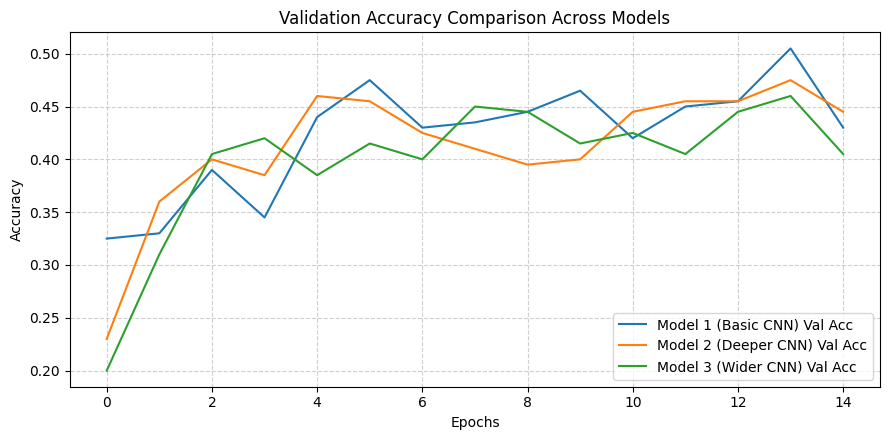

In [ ]:
models = {
    "Model 1 (Basic CNN)": (model_1, history_1),
    "Model 2 (Deeper CNN)": (model_2, history_2),
    "Model 3 (Wider CNN)": (model_3, history_3),
}

print(f"{'Model Name':<22} | {'Trainable Params':<18} | {'Train Acc':<10} | {'Val Acc':<10} | {'Test Acc':<10} | {'Test Loss':<10}")
print("-" * 95)

for name, (model, history) in models.items():
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    train_acc = history.history["accuracy"][-1]
    val_acc = history.history["val_accuracy"][-1]
    params = model.count_params()

    print(f"{name:<22} | {params:<18,d} | {train_acc:<10.4f} | {val_acc:<10.4f} | {test_acc:<10.4f} | {test_loss:<10.4f}")

# Plot Validation Accuracy Comparison
plt.figure(figsize=(9, 4.5))
for name, (_, history) in models.items():
    plt.plot(history.history["val_accuracy"], label=f"{name} Val Acc")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy Comparison Across Models")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

The results from this graph tell us that the models are severly overfitted on the train set, reducing test accuracy.
This can be fixed in next iteration by adjusting flattening, applying data augmentation or simply giving in more images ( larger train dataset ).

This is also reflective of the fact that the accuracy metric alone is not an 'accurate' evaluator of a models perfromance.

###**OPTIONAL WORK:**
I am fixing the accuracy of test set on model 1 using Augmentation Techniques

In [ ]:
# Define Data Augmentation Pipeline
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1, fill_mode="reflect"),
    tf.keras.layers.RandomZoom(height_factor=(-0.1, 0.1), width_factor=(-0.1, 0.1), fill_mode="reflect"),
    tf.keras.layers.RandomContrast(0.2)
], name="data_augmentation")

# Build Model 1 with Integrated Data Augmentation
def build_model_1_augmented(input_shape=(128, 128, 3), num_classes=5):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),

        # Apply Data Augmentation First
        data_augmentation,

        # Original Model 1 Architecture
        tf.keras.layers.Conv2D(16, kernel_size=(3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

        tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),  # Slightly increased dropout to further reduce overfitting
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ], name="Model_1_Augmented")

    return model

# Instantiate model
model_1_aug = build_model_1_augmented()
model_1_aug.summary()

# Compile the augmented model
model_1_aug.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the model
history_1_aug = model_1_aug.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

Model: "Model_1_Augmented"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │     2,097,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,102,629 (8.02 MB)

 Trainable params: 2,102,629 (8.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 568ms/step - accuracy: 0.2191 - loss: 1.8540 - val_accuracy: 0.2700 - val_loss: 1.5972
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 20s 511ms/step - accuracy: 0.2659 - loss: 1.5887 - val_accuracy: 0.3100 - val_loss: 1.5880
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 550ms/step - accuracy: 0.2776 - loss: 1.5572 - val_accuracy: 0.3100 - val_loss: 1.5560
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 20s 551ms/step - accuracy: 0.3278 - loss: 1.5168 - val_accuracy: 0.3500 - val_loss: 1.5047
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 19s 473ms/step - accuracy: 0.3813 - loss: 1.4623 - val_accuracy: 0.3750 - val_loss: 1.4670
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 10s 546ms/step - accuracy: 0.3779 - loss: 1.4370 - val_accuracy: 0.3950 - val_loss: 1.4460
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 24s 729ms/step - accuracy: 0.4314 - loss: 1.3766 - val_accuracy: 0.4400 - val_loss: 1.4036
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 584ms/step - accuracy: 0.4231 - loss: 1.3355 - val_accu

Training Accuracy:   0.6070
Validation Accuracy: 0.5050
Test Accuracy:       0.4350
Test Loss:           1.4137


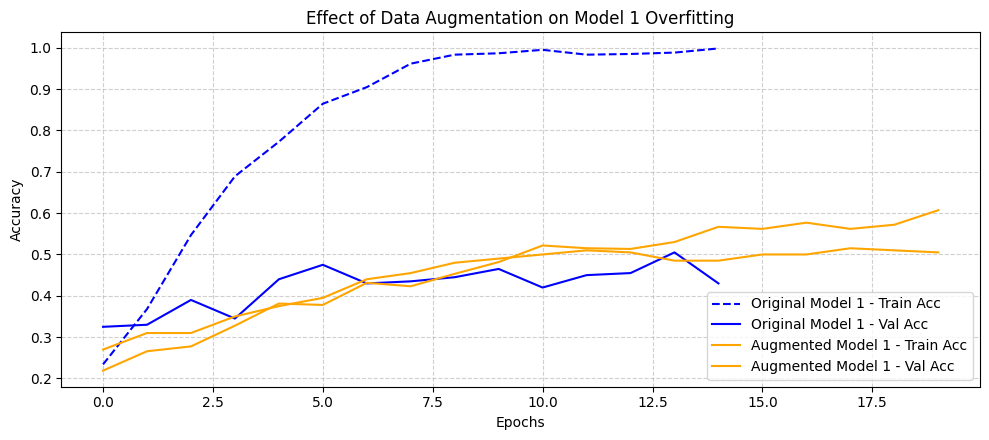

In [ ]:
#Compare:
# Evaluate on Test Data
test_loss_aug, test_acc_aug = model_1_aug.evaluate(x_test, y_test, verbose=0)
train_acc_aug = history_1_aug.history["accuracy"][-1]
val_acc_aug = history_1_aug.history["val_accuracy"][-1]

print(f"Training Accuracy:   {train_acc_aug:.4f}")
print(f"Validation Accuracy: {val_acc_aug:.4f}")
print(f"Test Accuracy:       {test_acc_aug:.4f}")
print(f"Test Loss:           {test_loss_aug:.4f}")

# Plot Accuracy Comparison
plt.figure(figsize=(10, 4.5))
plt.plot(history_1.history["accuracy"], label="Original Model 1 - Train Acc", linestyle="--", color="blue")
plt.plot(history_1.history["val_accuracy"], label="Original Model 1 - Val Acc", color="blue")

plt.plot(history_1_aug.history["accuracy"], label="Augmented Model 1 - Train Acc", color="orange")
plt.plot(history_1_aug.history["val_accuracy"], label="Augmented Model 1 - Val Acc", color="orange")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Effect of Data Augmentation on Model 1 Overfitting")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()